In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)


In [4]:
# Load the Heart Disease dataset
df = pd.read_csv("heart-disease.xls")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nClass Distribution:")
print(df["target"].value_counts())

Dataset Shape: (303, 14)

First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Class Distribution:
target
1    165
0    138
Name: count, dtype: int64


In [5]:
# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)
print("Data preprocessing completed!")


Training Data Shape: (242, 13)
Testing Data Shape: (61, 13)
Data preprocessing completed!


In [6]:
# Define SVM kernels
kernels = ["linear", "rbf", "poly"]

models = {}
results = []

for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0, degree=3)
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_score = model.decision_function(X_test_scaled)

    # Evaluation metrics
    results.append({
        "Kernel": kernel,
        "Support Vectors": model.n_support_.sum(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

    models[kernel] = model

print("All SVM models trained successfully!")

All SVM models trained successfully!


In [7]:
results_df = pd.DataFrame(results)

print("SVM Kernel Performance Comparison")
display(results_df.round(4))

SVM Kernel Performance Comparison


,Kernel,Support Vectors,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,linear,93,0.7869,0.7500,0.9091,0.8219,0.8842
1,rbf,143,0.8197,0.7750,0.9394,0.8493,0.8831
2,poly,148,0.8033,0.7442,0.9697,0.8421,0.9102


In [8]:
for kernel, model in models.items():
    print(f"\nKernel: {kernel}")
    print("Support Vectors per Class:", model.n_support_)
    print("Total Support Vectors:", model.n_support_.sum())
    print("Support Vector Coordinates (first 5):")
    print(model.support_vectors_[:5])


Kernel: linear
Support Vectors per Class: [45 48]
Total Support Vectors: 93
Support Vector Coordinates (first 5):
[[ 1.28205058  0.68313005  0.05747367  1.57559529  0.02336627 -0.40430377
   0.85749293 -1.37348581  1.39686059 -0.89045843 -0.6677359   2.16789598
  -2.21751422]
 [-0.79800184  0.68313005  1.05094704 -1.32016798 -0.03946303 -0.40430377
   0.85749293  0.0855367  -0.71589105 -0.89045843  0.94818498 -0.71469098
  -0.56122273]
 [ 0.40623903  0.68313005  0.05747367 -0.65191492  0.81920401 -0.40430377
  -1.02899151  0.45029233 -0.71589105  0.60485264 -0.6677359  -0.71469098
  -0.56122273]
 [ 1.17257414  0.68313005 -0.93599971 -1.20879247  0.06525246 -0.40430377
  -1.02899151  0.35910342 -0.71589105 -0.3920214   0.94818498  1.20703366
  -2.21751422]
 [ 1.0630977   0.68313005  1.05094704  0.46184018  1.88730203 -0.40430377
   0.85749293  0.35910342 -0.71589105 -0.89045843  0.94818498 -0.71469098
  -0.56122273]]

Kernel: rbf
Support Vectors per Class: [73 70]
Total Support Vectors

In [9]:
rbf_model = models["rbf"]

y_pred_rbf = rbf_model.predict(X_test_scaled)

print("Classification Report for RBF Kernel:\n")

print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=["No Heart Disease", "Heart Disease"],
    zero_division=0
))

Classification Report for RBF Kernel:

                  precision    recall  f1-score   support

No Heart Disease       0.90      0.68      0.78        28
   Heart Disease       0.78      0.94      0.85        33

        accuracy                           0.82        61
       macro avg       0.84      0.81      0.81        61
    weighted avg       0.83      0.82      0.82        61



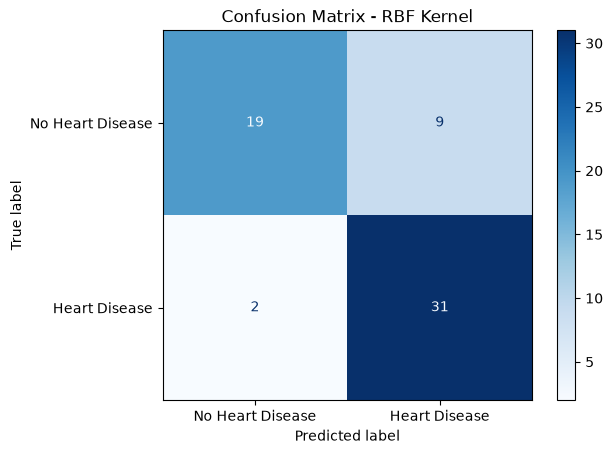

In [10]:
cm = confusion_matrix(y_test, y_pred_rbf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - RBF Kernel")
plt.show()

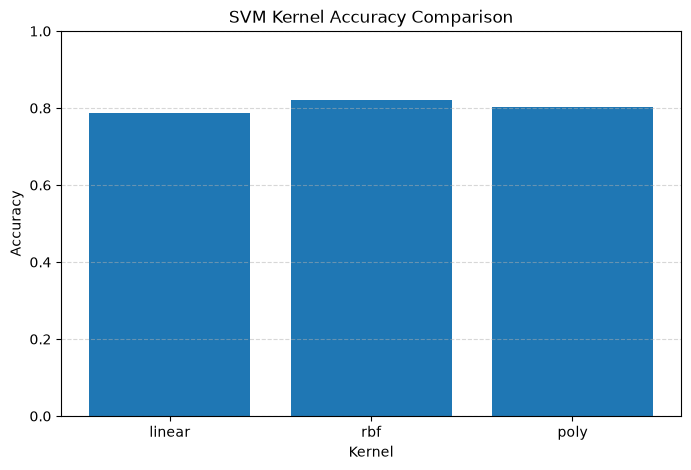

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy"]
)

plt.title("SVM Kernel Accuracy Comparison")
plt.xlabel("Kernel")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

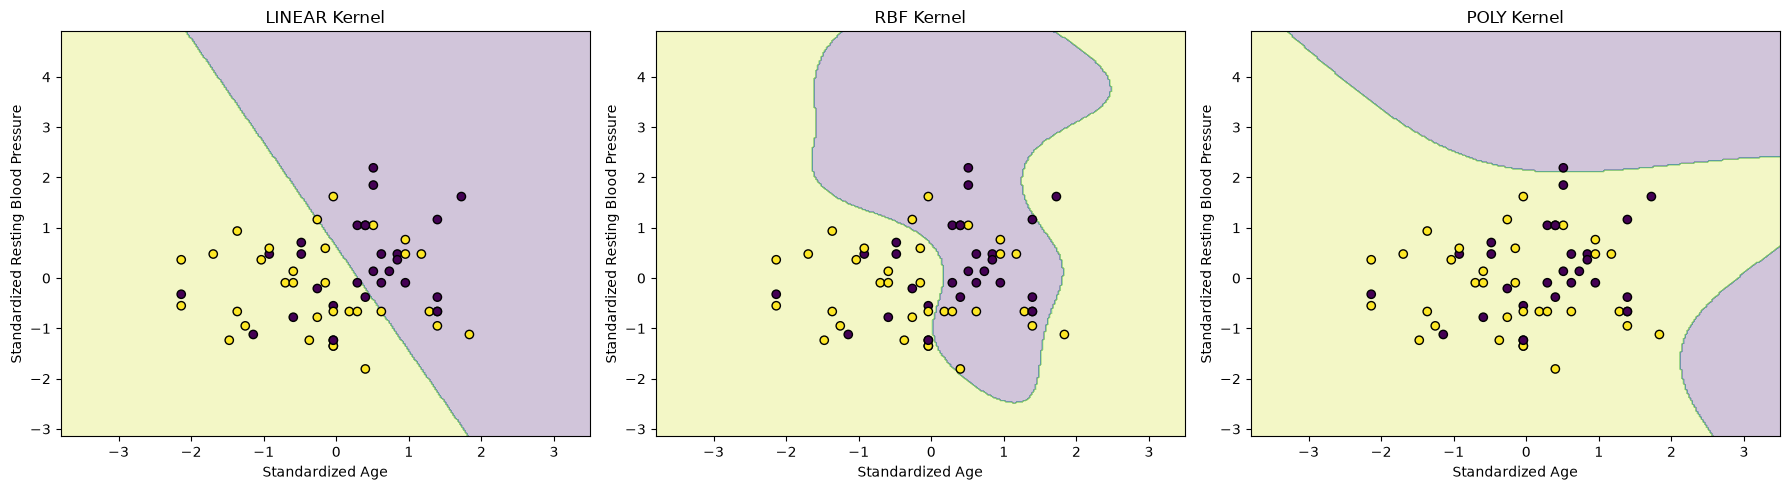

In [12]:
# Select two features for visualization
feature_names = ["age", "trestbps"]

X_2d = df[feature_names].values
y_2d = df["target"].values

# Scale the selected features
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# Train-test split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d_scaled,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# Create a mesh grid
x_min, x_max = X_2d_scaled[:, 0].min() - 1, X_2d_scaled[:, 0].max() + 1
y_min, y_max = X_2d_scaled[:, 1].min() - 1, X_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Plot decision boundaries for each kernel
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, kernel in zip(axes, kernels):
    model_2d = SVC(kernel=kernel, C=1.0, degree=3)
    model_2d.fit(X2_train, y2_train)

    Z = model_2d.predict(
        np.c_[xx.ravel(), yy.ravel()]
    ).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25)
    ax.scatter(
        X2_test[:, 0],
        X2_test[:, 1],
        c=y2_test,
        edgecolors="black"
    )

    ax.set_title(f"{kernel.upper()} Kernel")
    ax.set_xlabel("Standardized Age")
    ax.set_ylabel("Standardized Resting Blood Pressure")

plt.tight_layout()
plt.show()

In [13]:
best_kernel = results_df.loc[
    results_df["Accuracy"].idxmax(), "Kernel"
]

print("Best Kernel based on Accuracy:", best_kernel)

print("\nPerformance Summary:")
display(
    results_df.sort_values(
        by="Accuracy", ascending=False
    ).round(4)
)

Best Kernel based on Accuracy: rbf

Performance Summary:


,Kernel,Support Vectors,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,rbf,143,0.8197,0.7750,0.9394,0.8493,0.8831
2,poly,148,0.8033,0.7442,0.9697,0.8421,0.9102
0,linear,93,0.7869,0.7500,0.9091,0.8219,0.8842


In [14]:
print("Name :Manthan Mishra")
print ("PRN No.:72421206B")

Name :Manthan Mishra
PRN No.:72421206B
